# Workshop 2 — Silver Data Exploration

## 1. Introduction and Objectives

This notebook examines saved Silver Parquet outputs for NOAA HazEL historical tsunami observations. Bronze preserves the source responses; `src/silver.py` validates, types, deduplicates and records lineage in Silver. `src/load.py` maps Silver records to the canonical PostgreSQL model, but this notebook does not query the database. The goal is to inspect schema, missingness, quality, outliers, history and consistency across processing runs. Only one snapshot supplies the main descriptive results.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import pyarrow.parquet as pq
from IPython.display import display

project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sample_dir = project_root / "datalake_silver" / "samples"
if not sample_dir.is_dir():
    raise FileNotFoundError(f"Silver sample directory not found: {sample_dir}. Run from the repository root or notebooks/.")

## 2. Data Discovery and Loading

Discover the saved tsunami Parquet outputs through the repository-relative `datalake_silver/samples/` path. The earliest named snapshot is the representative dataset; later files are examined separately in Section 8. No snapshots are concatenated.

In [2]:
snapshot_paths = sorted(sample_dir.glob("tsunami_events_*.parquet"))
if not snapshot_paths:
    raise FileNotFoundError(f"No tsunami_events_*.parquet files found in {sample_dir}")
snapshot_path = snapshot_paths[0]
tsunamis = pd.read_parquet(snapshot_path)
print("Available snapshots:", *[p.name for p in snapshot_paths], sep="\n  ")
print(f"Representative snapshot: {snapshot_path.name} ({len(tsunamis)} rows)")
expected_fields = {"source", "external_id", "event_date", "event_time", "known_hour", "known_minute",
                   "seconds", "time_precision", "latitude", "longitude", "cause_code", "event_validity",
                   "region_code", "reported_eq_magnitude", "reported_eq_depth", "max_water_height",
                   "num_runups", "max_water_height_iqr_outlier", "bronze_file", "locator",
                   "bronze_manifest", "silver_processed_at", "content_hash"}
missing_fields = sorted(expected_fields - set(tsunamis.columns))
if missing_fields:
    raise ValueError(f"Expected Silver fields are missing: {missing_fields}")

Available snapshots:
  tsunami_events_20261116_235000.parquet
  tsunami_events_20261117_000000.parquet
  tsunami_events_20261117_001000.parquet
Representative snapshot: tsunami_events_20261116_235000.parquet (221 rows)


## 3. Dataset Overview and Schema Inspection

Inspect the record count, date coverage, source, types and Parquet schema. In `src/silver.py`, NOAA dates remain separate from full timestamps when clock components are incomplete. `event_time` is therefore nullable; `event_date`, `time_precision`, source identifiers, lineage fields and `content_hash` are expected Silver fields.

In [3]:
print(f"Shape: {tsunamis.shape[0]} rows × {tsunamis.shape[1]} columns")
print("Source counts:")
display(tsunamis["source"].value_counts().rename_axis("source").to_frame("rows"))
print(f"Event-date coverage: {tsunamis['event_date'].min()} to {tsunamis['event_date'].max()}")
print("Time precision:")
display(tsunamis["time_precision"].value_counts(dropna=False).rename_axis("precision").to_frame("rows"))

Shape: 221 rows × 28 columns
Source counts:


,rows
source,
noaa_hazel,221


Event-date coverage: 2010-01-02 to 2025-12-12
Time precision:


,rows
precision,
subsecond,109
second,80
day,23
minute,9


In [4]:
schema = pd.DataFrame({"column": tsunamis.columns, "pandas_dtype": tsunamis.dtypes.astype(str).values})
display(schema)
print(f"Parquet rows: {pq.ParquetFile(snapshot_path).metadata.num_rows}")
print("Parquet schema:")
print(pq.read_schema(snapshot_path))

,column,pandas_dtype
0,source,object
1,external_id,object
2,event_time,"datetime64[ns, UTC]"
3,event_date,object
4,known_hour,Int64
5,known_minute,Int64
6,seconds,float64
7,time_precision,object
8,latitude,float64
9,longitude,float64


Parquet rows: 221
Parquet schema:
source: string
external_id: string
event_time: timestamp[ns, tz=UTC]
event_date: date32[day]
known_hour: int64
known_minute: int64
seconds: double
time_precision: string
latitude: double
longitude: double
cause_code: int64
event_validity: int64
region_code: int64
warning_status_id: int64
noaa_earthquake_event_id: int64
reported_eq_magnitude: double
reported_eq_depth: double
max_water_height: double
num_runups: int64
oceanic_tsunami: bool
country: string
location_name: string
bronze_file: string
locator: string
max_water_height_iqr_outlier: bool
content_hash: string
bronze_manifest: string
silver_processed_at: timestamp[us, tz=UTC]
-- schema metadata --
pandas: '{"index_columns": [], "column_indexes": [], "columns": [{"name":' + 3627


## 4. Missing-Value Analysis

Nulls are retained rather than imputed. NOAA records can have only a date or partial clock time; the Silver processor leaves `event_time` null unless seconds are known. Missing earthquake magnitude and depth can also reflect a non-earthquake tsunami cause, as observed in Workshop 1. These are different from invalid values.

In [5]:
missing = pd.DataFrame({"missing": tsunamis.isna().sum()})
missing["percent"] = (missing["missing"] / len(tsunamis) * 100).round(1)
display(missing.sort_values(["missing", "percent"], ascending=False))

,missing,percent
warning_status_id,169,76.5
reported_eq_magnitude,35,15.8
reported_eq_depth,35,15.8
noaa_earthquake_event_id,34,15.4
event_time,32,14.5
seconds,32,14.5
known_hour,23,10.4
known_minute,23,10.4
max_water_height,12,5.4
latitude,9,4.1


In [6]:
cause_missing = pd.crosstab(tsunamis["cause_code"].eq(1).map({True: "earthquake cause (code 1)", False: "other codes (including mixed causes)"}),
                            tsunamis["reported_eq_magnitude"].isna(), rownames=["cause group"],
                            colnames=["reported earthquake magnitude missing"])
display(cause_missing)
print("Incomplete timestamps:", int(tsunamis["event_time"].isna().sum()))
print("Missing coordinates:", int((tsunamis["latitude"].isna() | tsunamis["longitude"].isna()).sum()))

reported earthquake magnitude missing,False,True
cause group,,
earthquake cause (code 1),179,0
other codes (including mixed causes),7,35


Incomplete timestamps: 32
Missing coordinates: 9


## 5. Data Quality and Validation

Check current-snapshot identifiers, valid geographic ranges, date/precision consistency, numeric plausibility and source lineage. A missing coordinate or measurement is reported separately from an invalid non-null value. These checks inspect Silver output; they do not re-run the normalization pipeline.

A populated lineage value shows where a record came from; file availability is checked separately. The saved Silver samples reference Bronze runs that are absent from the sample folder and the current local Bronze root. A 64-character hexadecimal hash passes a format check; that alone does not verify its content.

In [7]:
duplicate_keys = int(tsunamis.duplicated(["source", "external_id"]).sum())
invalid_lat = int((tsunamis["latitude"].notna() & ~tsunamis["latitude"].between(-90, 90)).sum())
invalid_lon = int((tsunamis["longitude"].notna() & ~tsunamis["longitude"].between(-180, 180)).sum())
invalid_numeric = {field: int(tsunamis[field].lt(0).sum()) for field in
                   ["reported_eq_magnitude", "reported_eq_depth", "max_water_height", "num_runups"]}
key_missing = tsunamis[["source", "external_id"]].isna().any(axis=1)
key_blank = tsunamis[["source", "external_id"]].astype("string").apply(lambda col: col.str.strip().eq("")).any(axis=1)
checks = pd.Series({"missing or blank observation keys": int((key_missing | key_blank).sum()),"duplicate (source, external_id) keys": duplicate_keys,
                    "invalid non-null latitudes": invalid_lat,
                    "invalid non-null longitudes": invalid_lon,
                    **{f"negative {key}": value for key, value in invalid_numeric.items()}})
display(checks.to_frame("count"))

,count
missing or blank observation keys,0
"duplicate (source, external_id) keys",0
invalid non-null latitudes,0
invalid non-null longitudes,0
negative reported_eq_magnitude,0
negative reported_eq_depth,0
negative max_water_height,0
negative num_runups,0


In [8]:
dated = pd.to_datetime(tsunamis["event_date"], errors="coerce")
timed = tsunamis["event_time"].notna()
time_checks = pd.Series({
    "unparseable or missing event dates": int(dated.isna().sum()),
    "full timestamps with different event date": int((timed & (tsunamis["event_time"].dt.date != dated.dt.date)).sum()),
    "full timestamps with incomplete precision": int((timed & ~tsunamis["time_precision"].isin(["second", "subsecond"])).sum()),
    "partial precision with a full timestamp": int((~timed & tsunamis["time_precision"].isin(["second", "subsecond"])).sum()),
})
display(time_checks.to_frame("count"))

,count
unparseable or missing event dates,0
full timestamps with different event date,0
full timestamps with incomplete precision,0
partial precision with a full timestamp,0


In [9]:
lineage_fields = ["bronze_file", "locator", "bronze_manifest", "content_hash"]
lineage = pd.DataFrame({"missing": tsunamis[lineage_fields].isna().sum(),
                        "blank": tsunamis[lineage_fields].astype(str).apply(lambda col: col.str.strip().eq("").sum())})
display(lineage)
print("Hashes not matching SHA-256 format:", int((~tsunamis["content_hash"].astype(str).str.fullmatch(r"[0-9a-f]{64}")).sum()))
print("Bronze files:", tsunamis["bronze_file"].nunique(),
      "| Bronze manifests:", tsunamis["bronze_manifest"].nunique())
bronze_root = project_root / "datalake_bronze"
references = sorted(set(tsunamis["bronze_file"]) | set(tsunamis["bronze_manifest"]))
display(pd.DataFrame([
    {"Bronze reference": name,
     "in Bronze sample folder": (bronze_root / "samples" / name).is_file(),
     "in local Bronze root": (bronze_root / name).is_file()}
    for name in references
]))

,missing,blank
bronze_file,0,0
locator,0,0
bronze_manifest,0,0
content_hash,0,0


Hashes not matching SHA-256 format: 0
Bronze files: 2 | Bronze manifests: 1


,Bronze reference,in Bronze sample folder,in local Bronze root
0,bronze_manifest_20261117_000917.json,False,False
1,noaa_hazel_page1_20261117_000917.json,False,False
2,noaa_hazel_page2_20261117_000917.json,False,False


In [10]:
rejected_paths = sorted(sample_dir.glob("rejected_records_*.parquet"))
if rejected_paths:
    print("Saved rejected-record outputs:")
    for path in rejected_paths:
        rejected = pd.read_parquet(path)
        print(f"{path.name}: {len(rejected)} rows")
        if not rejected.empty:
            display(rejected.head())
else:
    print("No rejected-record Parquet sample is available; quarantine contents cannot be assessed here.")

No rejected-record Parquet sample is available; quarantine contents cannot be assessed here.


## 6. Outlier Analysis

`src/silver.py` flags non-null heights outside $[Q_1 - 1.5\,IQR,\;Q_3 + 1.5\,IQR]$. It preserves flagged observations. The flag is a statistical screening result, not evidence that an extreme tsunami measurement is wrong.

In [11]:
height = tsunamis["max_water_height"].dropna()
q1, q3 = height.quantile([0.25, 0.75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
recomputed = tsunamis["max_water_height"].notna() & ((tsunamis["max_water_height"] < lower) | (tsunamis["max_water_height"] > upper))
print(f"Non-null heights: {len(height)}; Q1={q1:g} m, Q3={q3:g} m, IQR={iqr:g} m")
print(f"IQR bounds: {lower:g} to {upper:g} m")
print("Stored flags:", int(tsunamis["max_water_height_iqr_outlier"].sum()),
      "| Flag disagreements:", int((recomputed != tsunamis["max_water_height_iqr_outlier"]).sum()))
display(tsunamis.loc[tsunamis["max_water_height_iqr_outlier"],
                     ["external_id", "event_date", "max_water_height", "country", "location_name"]]
        .sort_values("max_water_height", ascending=False).head(10))

Non-null heights: 209; Q1=0.08 m, Q3=0.7 m, IQR=0.62 m
IQR bounds: -0.85 to 1.63 m
Stored flags: 33 | Flag disagreements: 0


,external_id,event_date,max_water_height,country,location_name
203,6045,2025-08-10,481.00,USA,"TRACY ARM, AK"
68,5596,2015-10-18,193.00,USA,"TAAN FJORD, AK"
219,6168,2022-09-01,170.00,CANADA,"ECSTALL RIVER, BC"
106,5714,2018-12-11,90.00,RUSSIA,"BUREYA, FAR EASTERN RUSSIA"
172,5929,2024-08-07,62.00,USA,"PEDERSEN LAGOON, AK"
15,5413,2011-03-11,39.26,JAPAN,HONSHU ISLAND
3,4682,2010-02-27,29.00,CHILE,CENTRAL CHILE
5,4762,2010-04-13,23.00,PERU,"513 LAKE, HUALCAN GLACIER"
134,5824,2022-01-15,22.00,TONGA,TONGA ISLANDS
202,6044,2025-07-29,17.00,RUSSIA,"KAMCHATKA PENINSULA, RUSSIA"


## 7. Historical Data Exploration

The following analyses use the representative 221-record snapshot only. Counts reflect saved NOAA observations, not a complete census of all Pacific tsunamis. Height is in meters; `reported_eq_magnitude` is the source's associated earthquake magnitude and is absent for some events. No magnitude scale is inferred for records without a documented type.

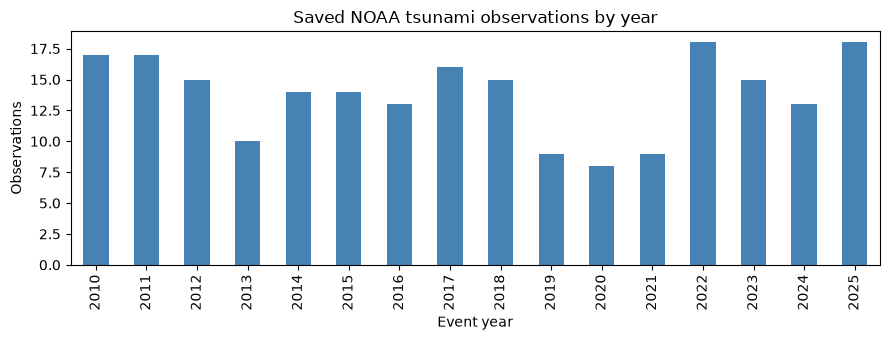

Yearly counts range from 8 to 18 across 16 years.


In [12]:
yearly = pd.to_datetime(tsunamis["event_date"]).dt.year.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(9, 3.5))
yearly.plot.bar(ax=ax, color="steelblue")
ax.set(title="Saved NOAA tsunami observations by year", xlabel="Event year", ylabel="Observations")
fig.tight_layout()
plt.show()
print(f"Yearly counts range from {yearly.min()} to {yearly.max()} across {len(yearly)} years.")

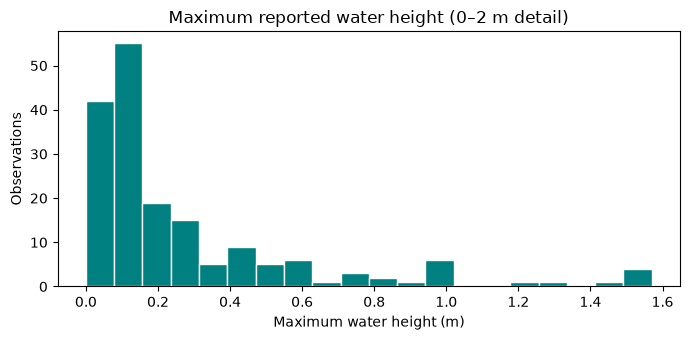

Measured heights: 209; median 0.2 m; maximum 481 m.
Plot shows 176 values up to 2 m; 33 larger values remain in the analysis.


In [13]:
shown_height = height[height <= 2]
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(shown_height, bins=20, color="teal", edgecolor="white")
ax.set(title="Maximum reported water height (0–2 m detail)", xlabel="Maximum water height (m)", ylabel="Observations")
fig.tight_layout()
plt.show()
print(f"Measured heights: {len(height)}; median {height.median():g} m; maximum {height.max():g} m.")
print(f"Plot shows {len(shown_height)} values up to 2 m; {len(height) - len(shown_height)} larger values remain in the analysis.")

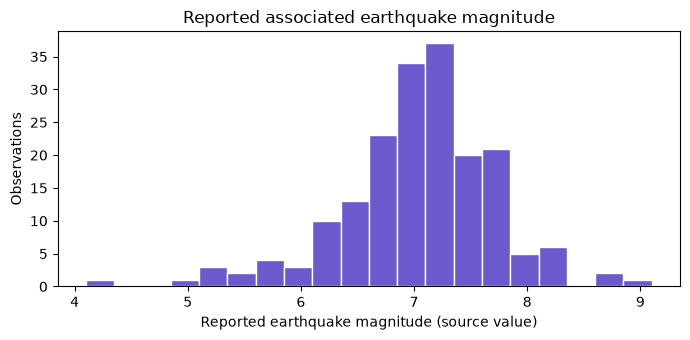

Reported magnitudes: 186; range 4.1–9.1. Missing values are excluded from this plot only.


In [14]:
magnitudes = tsunamis["reported_eq_magnitude"].dropna()
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(magnitudes, bins=20, color="slateblue", edgecolor="white")
ax.set(title="Reported associated earthquake magnitude", xlabel="Reported earthquake magnitude (source value)", ylabel="Observations")
fig.tight_layout()
plt.show()
print(f"Reported magnitudes: {len(magnitudes)}; range {magnitudes.min():g}–{magnitudes.max():g}. Missing values are excluded from this plot only.")

### Geographic distribution

Use the official NOAA descriptors saved in `workshop_1/samples/noaa_descriptor_*.json` (also reflected in `sql/02_reference_data.sql`). The ranking counts catalog observations by their original region code; it does not apply the separate Marine Regions polygon filter from Workshop 1. Code 82 contains the largest count (56), followed by Japan (code 85, 35).

In [15]:
descriptor_maps = {}
for kind in ["regions", "causes", "validity"]:
    descriptor_path = project_root / "workshop_1" / "samples" / f"noaa_descriptor_{kind}.json"
    if not descriptor_path.is_file():
        raise FileNotFoundError(f"Saved NOAA descriptor file is missing: {descriptor_path}")
    items = json.loads(descriptor_path.read_text(encoding="utf-8"))["items"]
    descriptor_maps[kind] = {int(item["id"]): item["description"] for item in items}

regions = tsunamis["region_code"].value_counts(dropna=False).rename_axis("region_code").reset_index(name="observations")
regions["NOAA description"] = regions["region_code"].map(descriptor_maps["regions"])
regions["percent"] = (100 * regions["observations"] / len(tsunamis)).round(1)
display(regions[["region_code", "NOAA description", "observations", "percent"]])

,region_code,NOAA description,observations,percent
0,82,"New Caledonia, New Guinea, Solomon Is., Vanuatu",56,25.3
1,85,Japan,35,15.8
2,81,"E. Australia, New Zealand, South Pacific Is.",32,14.5
3,89,West Coast of South America,23,10.4
4,88,West Coast of North and Central America,22,10.0
5,87,Alaska (including Aleutian Islands),18,8.1
6,84,"China, North and South Korea, Philippines, Taiwan",14,6.3
7,86,Kamchatka and Kuril Islands,14,6.3
8,83,E. Indonesia and Malaysia,6,2.7
9,80,"Hawaii, Johnston Atoll, Midway I",1,0.5


### Cause and catalog validity

Keep NOAA cause and validity codes separate: a cause describes the proposed generating mechanism, while validity describes confidence in the tsunami entry. In this snapshot, validity code 4 means **Definite Tsunami**, 3 **Probable Tsunami**, 2 **Questionable Tsunami**, and −1 **Erroneous entry**. No record has code 1 (**Very Doubtful Tsunami**) or 0 (seiche only). The erroneous entry is retained by the current Silver implementation and must not be interpreted as a confirmed tsunami.

Cause code 1 is earthquake only; codes 3 and 4 include an earthquake together with another mechanism. Thus, the “other codes” row in Section 4 includes mixed and unknown causes, in addition to non-earthquake mechanisms.

In [16]:
for field, kind in [("cause_code", "causes"), ("event_validity", "validity")]:
    counts = tsunamis[field].value_counts(dropna=False).sort_index().rename_axis(field).reset_index(name="observations")
    counts["NOAA description"] = counts[field].map(descriptor_maps[kind])
    counts["percent"] = (100 * counts["observations"] / len(tsunamis)).round(1)
    print(field)
    display(counts[[field, "NOAA description", "observations", "percent"]])

cause_code


,cause_code,NOAA description,observations,percent
0,0,Unknown,2,0.9
1,1,Earthquake,179,81.0
2,3,Earthquake and Landslide,5,2.3
3,4,Volcano and Earthquake,1,0.5
4,6,Volcano,6,2.7
5,7,Volcano and Landslide,2,0.9
6,8,Landslide,17,7.7
7,9,Meteorological,9,4.1


event_validity


,event_validity,NOAA description,observations,percent
0,-1,Erroneous entry,1,0.5
1,2,Questionable Tsunami,8,3.6
2,3,Probable Tsunami,33,14.9
3,4,Definite Tsunami,179,81.0


### Reported earthquake magnitude and maximum water height

Use complete pairs with earthquake-only cause code 1 and probable/definite validity (3–4), while retaining the original dataset for the other analyses. The 170 pairs give a moderate positive descriptive association (Pearson ≈ 0.444; Spearman ≈ 0.470). Magnitude is not tsunami severity. Maximum reported water height can include local run-up and is not necessarily an open-ocean wave height. The broader catalog includes non-earthquake causes and extreme local run-ups; the restricted sample, reporting gaps and catalog selection limit interpretation. Correlation does not establish causation.

Complete pairs: 170; Pearson r=0.444; Spearman rho=0.470


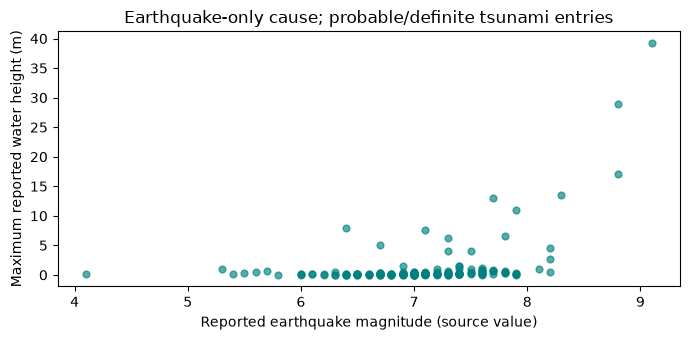

In [17]:
paired = tsunamis.loc[tsunamis["cause_code"].eq(1) & tsunamis["event_validity"].isin([3, 4]),
                      ["reported_eq_magnitude", "max_water_height"]].dropna()
if len(paired) >= 3 and paired.nunique().min() > 1:
    pearson = paired["reported_eq_magnitude"].corr(paired["max_water_height"])
    spearman = paired["reported_eq_magnitude"].rank().corr(paired["max_water_height"].rank())
    print(f"Complete pairs: {len(paired)}; Pearson r={pearson:.3f}; Spearman rho={spearman:.3f}")
    fig, ax = plt.subplots(figsize=(7, 3.5))
    ax.scatter(paired["reported_eq_magnitude"], paired["max_water_height"], alpha=0.65, color="teal", s=24)
    ax.set(title="Earthquake-only cause; probable/definite tsunami entries",
           xlabel="Reported earthquake magnitude (source value)", ylabel="Maximum reported water height (m)")
    fig.tight_layout()
    plt.show()
else:
    print("Insufficient complete, varying pairs for a meaningful association analysis.")

## 8. Silver Processing Runs Comparison

Compare each file independently by row count, column schema, `(source, external_id)` and `content_hash`. Lineage and processing timestamps may differ between runs even when the scientific observations and their content hashes agree. This checks Silver-output consistency, **not** PostgreSQL idempotency or successful database loading.

The comparison also checks all stored observation values apart from file lineage, record locators and processing timestamps: the production hash covers selected fields rather than every Silver column.

In [18]:
snapshots = {path.name: pd.read_parquet(path) for path in snapshot_paths}
summary = pd.DataFrame([
    {"snapshot": name, "rows": len(frame), "columns": len(frame.columns),
     "unique_keys": frame[["source", "external_id"]].drop_duplicates().shape[0],
     "unique_hashes": frame["content_hash"].nunique(),
     "bronze_manifests": frame["bronze_manifest"].nunique()}
    for name, frame in snapshots.items()
]).set_index("snapshot")
display(summary)

,rows,columns,unique_keys,unique_hashes,bronze_manifests
snapshot,,,,,
tsunami_events_20261116_235000.parquet,221,28,221,221,1
tsunami_events_20261117_000000.parquet,221,28,221,221,1
tsunami_events_20261117_001000.parquet,221,28,221,221,1


In [19]:
keys = ["source", "external_id"]
reference_rows = tsunamis.set_index(keys).sort_index()
observation_columns = tsunamis.columns.difference(keys + ["bronze_file", "locator", "bronze_manifest", "silver_processed_at"])
comparison = []
for name, frame in snapshots.items():
    if frame[keys].isna().any(axis=None) or frame.duplicated(keys).any():
        raise ValueError(f"Missing or duplicate observation keys in {name}")
    indexed = frame.set_index(keys).sort_index()
    shared = reference_rows.index.intersection(indexed.index)
    comparison.append({"snapshot": name,
                       "same_column_schema": frame.columns.tolist() == tsunamis.columns.tolist() and frame.dtypes.equals(tsunamis.dtypes),
                       "same_keys": reference_rows.index.equals(indexed.index),
                       "shared_keys": len(shared),
                       "different_hashes_on_shared_keys": int((reference_rows.loc[shared, "content_hash"] != indexed.loc[shared, "content_hash"]).sum()),
                       "same_observation_values": reference_rows[observation_columns].equals(indexed.reindex(index=reference_rows.index, columns=observation_columns))})
display(pd.DataFrame(comparison).set_index("snapshot"))

,same_column_schema,same_keys,shared_keys,different_hashes_on_shared_keys,same_observation_values
snapshot,,,,,
tsunami_events_20261116_235000.parquet,True,True,221,0,True
tsunami_events_20261117_000000.parquet,True,True,221,0,True
tsunami_events_20261117_001000.parquet,True,True,221,0,True


## 9. Canonical Database Model Readiness

The mappings below follow `src/load.py` and `sql/01_schema.sql`; they describe intended loading, not observed PostgreSQL rows.

| Silver field(s) | Canonical destination | Meaning |
|---|---|---|
| `source`, `external_id` | `event.source`, `event.external_id` | Current observation key, unique per source. |
| `event_time`, `event_date`, `known_hour`, `known_minute`, `time_precision` | `event.timestamp`, date and precision fields | Preserves partial NOAA times; complete times use the Silver UTC interpretation, whose source timezone still needs confirmation. |
| `latitude`, `longitude` | `event.latitude`, `event.longitude` | Nullable WGS84 coordinates. |
| `max_water_height` | `event.severity` and `tsunami_event.max_water_height` | Maximum reported height, in meters; `event.severity_scale` is `tsunami_max_water_height`. |
| `cause_code`, `event_validity`, `region_code`, `warning_status_id` | `tsunami_event` and NOAA reference catalogs | Original NOAA coded descriptors. |
| `reported_eq_magnitude`, `reported_eq_depth`, `num_runups`, `country`, `location_name` | `tsunami_event` | Source attributes; depth is in km, water height is in m. |
| `bronze_file`, `locator`, `content_hash` | `event.raw_reference`, `event.content_hash` | File and record lineage plus change detection. |

`bronze_manifest` and `silver_processed_at` describe the Silver run; the current loader does not insert them as `event` columns. The IQR flag is a Silver quality indicator and is not a `tsunami_event` column.

## 10. Conclusions

The saved samples contain three separately readable 221-row, 28-column Silver outputs. The representative file covers 2010-01-02 through 2025-12-12. Its `(source, external_id)` keys are unique, all non-null coordinates fall within valid ranges, and the saved lineage fields are populated and hashes match the SHA-256 format. Thirty-two records lack a complete timestamp, nine lack coordinates, and 12 lack maximum water height; these nulls remain unfilled. Of 209 measured heights, 33 carry the existing IQR flag, including extreme values that are retained for scientific review.

The three saved files have the same keys, schemas, per-key content hashes and stored observation values apart from lineage and processing timestamps; they represent repeated processing of the same 221 observations, not 663 unique events. The Bronze filenames and manifests differ between runs. These references identify source files, but the linked Bronze runs are absent from the supplied sample folder and the current local Bronze root, preventing a full source-to-Silver check here. This notebook cannot establish whether PostgreSQL accepted those records or whether database upserts were idempotent. No rejected-record Parquet sample is available here, so quarantine contents are also outside this inspection.

The most represented NOAA region is code 82 (New Caledonia, New Guinea, Solomon Is., Vanuatu), with 56 observations. Catalog certainty varies: 179 are definite, 33 probable, 8 questionable and 1 is an erroneous entry; these categories should not be pooled as equally confirmed tsunamis. There are 179 records with earthquake-only cause code 1, plus 6 with mixed causes involving an earthquake. Among 170 complete magnitude/height pairs restricted to cause code 1 and probable/definite validity, Pearson correlation is about 0.444 and Spearman correlation about 0.470. These describe a selected sample and provide no causal or predictive validation.